# So sánh các kernel và ảnh hưởng của gamma với kernel RBF (mục 7.1.3)

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Cùng dữ liệu với codes/05_svm_kernels.ipynb

In [2]:
X, y = make_moons(n_samples=300, noise=0.3, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 300), np.linspace(-1.3, 1.8, 300))

configs = [('Tuyến tính', {'kernel': 'linear'}),
           ('Đa thức bậc 3', {'kernel': 'poly', 'degree': 3, 'coef0': 1}),
           ('RBF, $\\gamma$ = 1', {'kernel': 'rbf', 'gamma': 1}),
           ('RBF, $\\gamma$ = 0.1', {'kernel': 'rbf', 'gamma': 0.1}),
           ('RBF, $\\gamma$ = 1', {'kernel': 'rbf', 'gamma': 1}),
           ('RBF, $\\gamma$ = 50', {'kernel': 'rbf', 'gamma': 50})]

Vẽ hình và lưu ảnh.

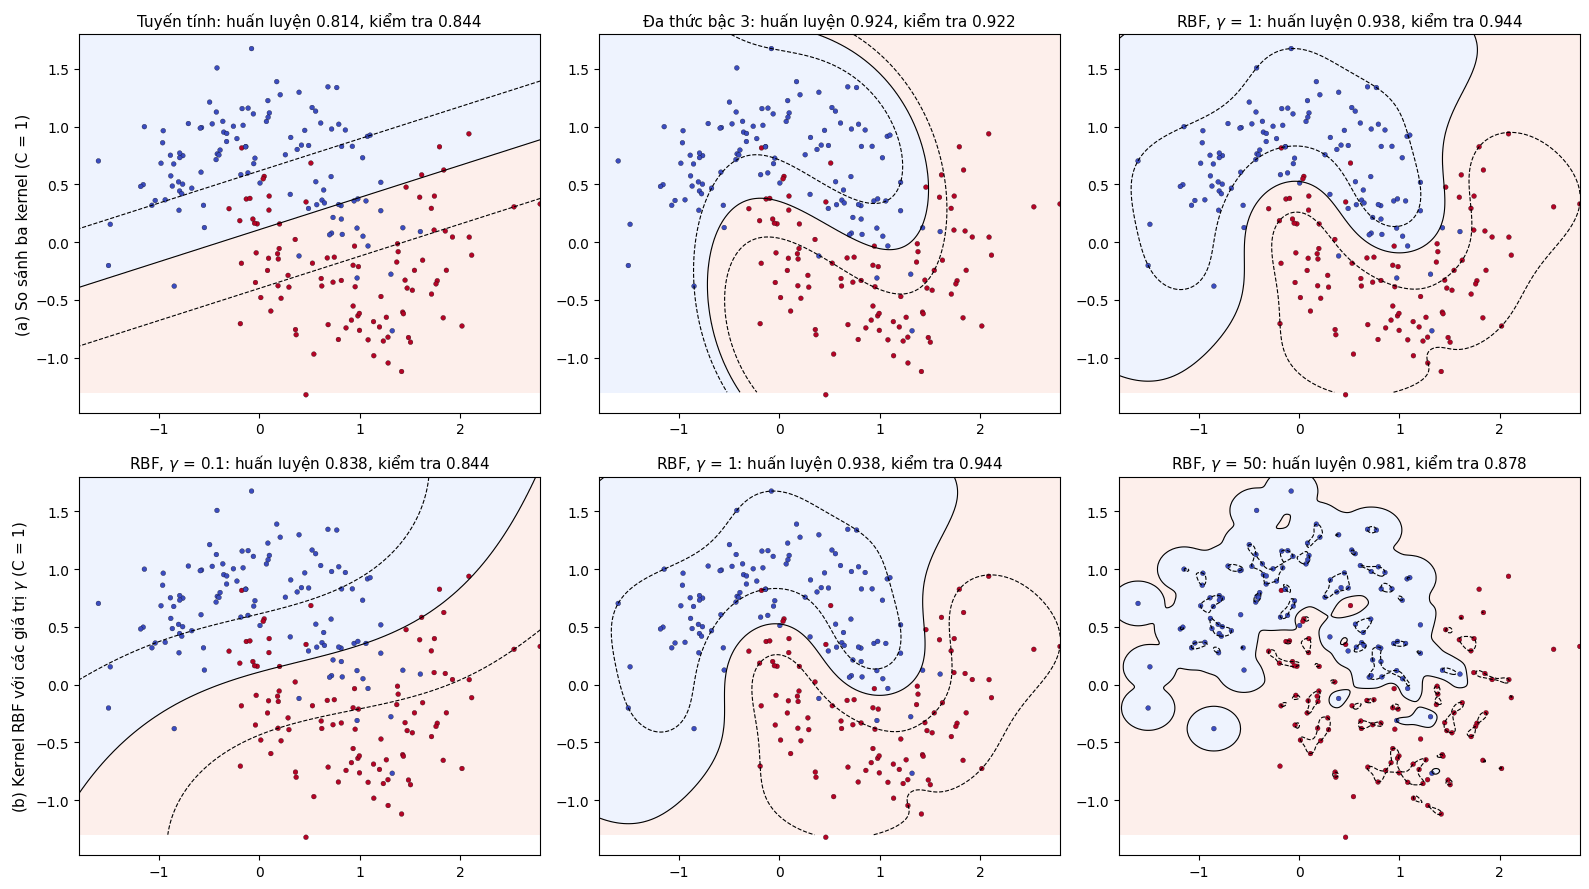

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, params) in zip(axes.ravel(), configs):
    model = make_pipeline(StandardScaler(), SVC(C=1, **params)).fit(X_train, y_train)
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz > 0, alpha=0.15, cmap='coolwarm')
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=0.8)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', s=12, edgecolors='k', linewidths=0.2)
    ax.set_title('%s: huấn luyện %.3f, kiểm tra %.3f'
                 % (name, model.score(X_train, y_train), model.score(X_test, y_test)), fontsize=11)
axes[0, 0].set_ylabel('(a) So sánh ba kernel (C = 1)', fontsize=11)
axes[1, 0].set_ylabel('(b) Kernel RBF với các giá trị $\\gamma$ (C = 1)', fontsize=11)
fig.tight_layout()
fig.savefig(IMAGES / 'svm_kernels.png', dpi=150)